# 05B · NFL outcome reliability and target freeze

**Advanced movement programme — Milestone 05, part B.** Status: `AUTHORED — AWAITING USER EXECUTION` (2026-10-13). No cell has been run by the author.

**Question.** Which NFL movement outcomes are reproducible for an athlete across *independent games*, at which exposure, under which context and filter choices — and which one (with at most two secondaries) is frozen as the target of the Combine-to-NFL transfer study?

**Rules of this notebook.**

- Every split is a split of an athlete's **games**, never of frames or plays. Every interval resamples **athletes**.
- **No Combine value is read.** The play table, the screening and the freeze take NFL evidence only; a Combine-prefixed column stops the code. Target selection cannot depend on a Combine association.
- Reference lines are documented heuristics. The rule-based screen is a proposal; the decision is recorded by the analyst with a rationale, and `STOP` is an acceptable outcome.
- Reliability shows that a value repeats for an athlete. Role, scheme and usage repeat too: a reliable outcome is not thereby an athletic capability.

**How to run.** Run notebook 05A first in the same `RUN_MODE`. Smoke first (technical check), then `RUN_MODE = 'full'` after a kernel restart. After the full run, set `DECISION` in section 10 and rerun from that cell.

## Configuration

In [1]:
RUN_MODE = 'full'           # 'smoke' | 'full' — must match the mode notebook 05A was run with
FORCE_REBUILD = False        # True = recompute the reliability tables even when they are current
SAVE_TABLES = True
SAVE_FIGURES = True
SAVE_MODELS = False          # unused: nothing is trained in Milestone 05
SEED = 20261011              # same seed as notebook 05A
MAX_ATHLETES = None          # unused here: the athlete subset is fixed by notebook 05A
DEVICE = 'cpu'               # unused here
NUM_WORKERS = 0              # unused here
EXPERIMENT_VERSION = '1'     # version of the NFL outcome definitions
BOOTSTRAP_ITERATIONS = 1000  # athlete bootstrap replicates (smoke: 100)
GAME_SPLITS = 100            # random half-splits of each athlete's games (smoke: 10)
REFREEZE_TARGETS = False     # True = replace an existing nfl_movement_targets_v1.json (only if no transfer analysis has used it)

In [2]:
from dataclasses import replace

from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)    # thread and memory limits; call before the first polars import of the kernel

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import file_fingerprint
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import nfl_outcome_figures as nf
from nflbdb.research.advanced_movement import nfl_outcome_validation
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import outcome_reliability as orl
from nflbdb.research.advanced_movement.artifacts import NflOutcomeStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES,
                                save_tables=SAVE_TABLES, save_models=SAVE_MODELS, device=DEVICE, seed=SEED,
                                num_workers=NUM_WORKERS).validate()
if EXPERIMENT_VERSION != no.OUTCOMES_VERSION:
    raise ValueError(f'EXPERIMENT_VERSION = {EXPERIMENT_VERSION!r} but the outcome definitions are version {no.OUTCOMES_VERSION!r}')
c = replace(no.OutcomeConfig(version=EXPERIMENT_VERSION), n_boot=int(BOOTSTRAP_ITERATIONS), n_game_splits=int(GAME_SPLITS)).for_mode(controls)
store = NflOutcomeStore(cfg, controls)
seed_notes = amc.seed_everything(controls.seed)

NB05A, NB05B = '05a_nfl_movement_outcome_eda.ipynb', '05b_nfl_outcome_reliability_and_freeze.ipynb'
PLAYS, VARIANTS, COVERAGE = no.plays_contract(c), no.variants_contract(c), no.coverage_contract(c)
plays = store.require(PLAYS, NB05A)
variants = store.require(VARIANTS, NB05A)
dictionary = store.require(no.DICTIONARY, NB05A)
outcomes = store.require(no.ATHLETE_OUTCOMES, NB05A)
coverage = store.require(COVERAGE, NB05A)
upstream = store.read_json('nfl_outcome_manifest', NB05A)
if upstream.get('definition_hash') != no.definition_hash(c):
    raise ValueError('the play table of notebook 05A was built under another outcome definition '
                     f'({upstream.get("definition_hash")} against {no.definition_hash(c)}): rerun 05A with this configuration')
if upstream.get('seed') != controls.seed:
    raise ValueError(f'SEED = {controls.seed} but notebook 05A was run with seed {upstream.get("seed")}: use the same seed')
for name, table in (('play table', plays), ('athlete outcomes', outcomes), ('coverage', coverage), ('dictionary', dictionary)):
    no.assert_no_combine_columns(table, name)

eng = no.OutcomeEngine(plays, c)
THR, GE = c.primary_min_windows, f'n_athletes_ge_{c.primary_min_windows}'
PLAY_FILES = [store.parquet(PLAYS), store.parquet(VARIANTS)]
FIGURES = []
label = 'TECHNICAL CHECK ONLY — a few games per season; no number below is a result' if controls.smoke else 'full population'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {eng.plays.height:,} eligible windows of {eng.athletes.height} athletes · '
                 f'{len(eng.specs)} outcomes · {c.n_boot} bootstrap replicates, {c.n_game_splits} game half-splits · seed {controls.seed}'))
display(store.describe())

**Run mode: `full`** (full population) · 242,043 eligible windows of 401 athletes · 21 outcomes · 1000 bootstrap replicates, 100 game half-splits · seed 20261011

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Inputs and cohort

The inputs are the artifacts of notebook 05A in the same run mode: the play table (one row per tracked player-play), the measure variants, the outcome dictionary, the athlete values and the coverage table. No tracking frame is read here and no Combine table is opened.

In [3]:
per_athlete = eng.plays.group_by('position_group', 'nfl_id').agg(pl.len().alias('n'), pl.col('game_id').n_unique().alias('g'),
                                                               pl.col('season').n_unique().alias('s'))
cohort = (per_athlete.group_by('position_group')
          .agg(pl.len().alias('athletes'), (pl.col('n') >= THR).sum().alias(f'athletes_ge_{THR}_windows'), (pl.col('g') >= 4).sum().alias('athletes_ge_4_games'),
               (pl.col('s') >= 2).sum().alias('athletes_in_2_seasons'), pl.col('n').median().alias('median_windows'),
               pl.col('g').median().alias('median_games')).sort('position_group'))
display(Markdown('**Athletes available to the reliability study** (unit: athlete with ≥ 1 eligible window)'))
display(cohort)
display(Markdown('**Candidate outcomes and their coverage at the primary threshold** (unit: athlete)'))
with pl.Config(tbl_rows=40, fmt_str_lengths=90, float_precision=3):
    display(dictionary.select('outcome_id', 'role', 'unit', 'label')
            .join(coverage.filter(pl.col('position_group') == no.ALL).select('outcome_id', 'n_athletes_any', GE, 'opportunity_rate'), on='outcome_id')
            .sort('outcome_id'))

**Athletes available to the reliability study** (unit: athlete with ≥ 1 eligible window)

position_group,athletes,athletes_ge_50_windows,athletes_ge_4_games,athletes_in_2_seasons,median_windows,median_games
str,u32,u32,u32,u32,f64,f64
"""DB""",96,78,80,56,416.5,15.0
"""DL""",98,88,91,54,289.5,17.0
"""OL""",91,77,76,50,747.0,15.0
"""TE""",33,23,29,19,183.0,17.0
"""WR""",83,70,79,47,292.0,17.0


**Candidate outcomes and their coverage at the primary threshold** (unit: athlete)

outcome_id,role,unit,label,n_athletes_any,n_athletes_ge_50,opportunity_rate
str,str,str,str,i64,i64,f64
"""O1.speed_max_p95""","""reference""","""yd/s""","""single-frame peak speed (p95 of windows)""",401,336,1.000
"""O1.speed_p90_mean""","""candidate""","""yd/s""","""play p90 speed (mean of windows)""",401,336,1.000
"""O1.speed_sust05_p90""","""candidate""","""yd/s""","""sustained speed, 0.5 s (p90 of windows)""",401,336,1.000
"""O1.speed_sust10_p90""","""candidate""","""yd/s""","""sustained speed, 1 s (p90 of windows)""",401,336,1.000
"""O2.accel_sust05_mean""","""candidate""","""yd/s²""","""sustained acceleration, 0.5 s (mean of windows)""",401,336,0.999
"""O2.accel_sust05_p90""","""candidate""","""yd/s²""","""sustained acceleration, 0.5 s (p90 of windows)""",401,336,0.999
"""O2.accel_sust10_p90""","""candidate""","""yd/s²""","""sustained acceleration, 1 s (p90 of windows)""",401,336,0.997
"""O3.band_acc_v0_2_mean""","""candidate""","""yd/s²""","""acceleration from 0–2 yd/s (mean of windows)""",401,336,0.978
"""O3.band_acc_v2_4_mean""","""candidate""","""yd/s²""","""acceleration from 2–4 yd/s (mean of windows)""",400,333,0.882


## 2 · Synthetic validation

Eight checks on synthetic play tables with a known answer: recovery of a closed-form reliability from game half-splits (and the inflation obtained when windows of the same game are split instead), time order and non-overlap of the exposure budgets, removal of position means, context adjustment, missingness and composites, the freeze rules, the absence of any Combine source, and the whole table pipeline against its contracts. Every row must read `PASS`.

In [4]:
validation_report = nfl_outcome_validation.run_all(nfl_outcome_validation.CHECKS_05B)
with pl.Config(tbl_rows=30, fmt_str_lengths=400, tbl_width_chars=200):
    display(validation_report)
nfl_outcome_validation.assert_all_passed(validation_report)

11:05:58 | INFO    | nflbdb.research.advanced_movement.outcome_reliability | [nfl_outcomes] nfl_movement_targets_v1.json written: decision FREEZE, targets ['O1.speed_sust10_p90', 'O2.accel_sust05_mean']
11:05:58 | INFO    | nflbdb.research.advanced_movement.outcome_reliability | [nfl_outcomes] nfl_movement_targets_v1.json written: decision STOP, targets []


check,status,detail
str,str,str
"""game_grouped_reliability""","""PASS""","""closed-form reliability 0.792: odd / even games 0.759 [0.718, 0.793], random halves 0.771, on 300 athletes; with a strong game effect a window split reads 0.967 where the game split reads 0.674 (truth 0.718)"""
"""exposure_thresholds_keep_time_order""","""PASS""","""the first-N value uses the athlete's first N windows in time; its reference uses only games played after them (no shared game); athletes without the budget are absent; projected reliability rises with exposure (0.77 → 0.97); smoke mode changes budgets, never a measure definition"""
"""season_and_position_grouping""","""PASS""","""three positions with different means and NO athlete effect: pooled half-split correlation 0.99, within position -0.02; estimates exist per position group and between consecutive seasons"""
"""context_comparability""","""PASS""","""an alignment effect of 2 yd/s with athletes differing in alignment mix: athlete value follows the mix (r = 0.97) until cell means are removed (r = +0.03); η² of alignment 0.49; a cell with fewer than 10 windows is left unadjusted and flagged"""
"""missingness_and_composites""","""PASS""","""undefined windows are excluded from the statistic and counted as excluded (240 of 1,920, opportunity rate 0.875); an athlete lacking one speed band has no envelope value instead of an average"""
"""target_freeze""","""PASS""","""nothing is written while the decision is pending; reference, not-eligible and unexplained provisional outcomes are refused; the artifact carries formula, units, context, exposure, reliability, counts and hashes; a second freeze is kept apart unless REFREEZE is set; a near-duplicate outcome is not proposed as a secondary; no eligible outcome → STOP"""
"""no_combine_access""","""PASS""","""3 module files name no Combine table or representation; a Combine-prefixed column stops the engine and the freeze; the screening, proposal and freeze functions take NFL evidence only"""
"""engine_end_to_end""","""PASS""","""21 outcomes on 90 synthetic athletes pass every table contract; planted repeatable outcome reliability 0.97 (eligible), planted noise 0.00 (not eligible); rule-based proposal FREEZE (primary O3.band_acc_v2_4_mean)"""


## 3 · Statistical methods

| Quantity | Definition | What it separates |
|---|---|---|
| `game_odd_even` | Pearson between the outcome computed on an athlete's odd games and on the even games (chronological game order), position-group means removed; 95 % athlete bootstrap | deterministic split with a sampling interval |
| `game_odd_even_sb` | the same, stepped up to all games (Spearman–Brown) | reliability of the value on ALL the athlete's games |
| `game_random_halves_sb` | mean over random half-splits of each athlete's games, stepped up; the interval is the spread over splits, not a sampling interval | dependence on one particular split |
| `play_icc1`, `game_icc1` | ICC(1) of single windows / of athlete-game means of the play measure, stratified by position | per-window noise, per-game variability |
| `var_athlete`, `var_game`, `var_window` | one-way moment estimators of the play-measure variance | athlete-level stability against game and window noise |
| `season_a_to_b` | Pearson between the outcome on two consecutive seasons (not stepped up) | stability across seasons, mixed with real change |
| `first_vs_later_games` | Pearson between the outcome on the athlete's FIRST N windows (or G games) and on the games played strictly after them | what a limited early exposure tells; attenuated by the noise of both sides |
| `within_budget_game_split_sb` | odd / even games inside the first N windows, stepped up | reliability of the first-N value itself |
| `model_projection` | σ²ₐ / (σ²ₐ + σ²_g / G + σ²_w / N) from the variance components | expected reliability of an athlete MEAN at a budget |

Thresholds on exposure are applied to the NFL windows only; no threshold depends on Combine predictor availability. A group with fewer athletes than the stated minimum has no estimate. The context-adjusted variant removes the mean of the context cell (position group × alignment × play class) computed on all athletes — a descriptive adjustment; a predictive evaluation must rebuild the cell means on training athletes.

## 4 · Reliability across independent games

In [5]:
reliability = store.build('NFL_RELIABILITY', [orl.RELIABILITY], lambda: {orl.RELIABILITY.name: orl.reliability_table(eng, c)},
                          params=c.params(), files=PLAY_FILES)[orl.RELIABILITY.name]
at_thr = reliability.filter((pl.col('min_windows') == THR) & (pl.col('group') == orl.WITHIN))


def wide(method: str, adjustment: str = 'raw') -> pl.DataFrame:
    r = at_thr.filter((pl.col('method') == method) & (pl.col('adjustment') == adjustment))
    return r.select('outcome_id', 'n_athletes', pl.col('estimate').alias(method), pl.col('ci_lower').alias(f'{method}_lower'),
                    pl.col('ci_upper').alias(f'{method}_upper'))


main = (wide('game_odd_even_sb').join(wide('game_random_halves_sb').drop('n_athletes'), on='outcome_id', how='left')
        .join(wide('game_random_halves_sb', 'context').select('outcome_id', pl.col('game_random_halves_sb').alias('random_halves_context_adjusted')),
              on='outcome_id', how='left').sort('game_random_halves_sb', descending=True, nulls_last=True))
display(Markdown(f'**Reliability across games, within position** (unit: athlete with ≥ {THR} eligible windows; stepped up to all games)'))
with pl.Config(tbl_rows=40, float_precision=3):
    display(main)
display(Markdown('**Reliability against the exposure threshold** (unit: athlete; random game half-splits, stepped up; a higher threshold keeps fewer, more-exposed athletes)'))
by_thr = reliability.filter((pl.col('method') == 'game_random_halves_sb') & (pl.col('adjustment') == 'raw') & (pl.col('group') == orl.WITHIN))
with pl.Config(tbl_rows=40, float_precision=3):
    display(by_thr.pivot(on='min_windows', index='outcome_id', values='estimate').sort('outcome_id'))
    display(by_thr.pivot(on='min_windows', index='outcome_id', values='n_athletes').sort('outcome_id'))
display(Markdown('**Variance of the play measure: athlete, game, window** (unit: eligible window; squared unit of the measure; ICCs beside)'))
components = (reliability.filter((pl.col('adjustment') == 'raw') & pl.col('method').is_in(['var_athlete', 'var_game', 'var_window', 'windows_per_game', 'play_icc1', 'game_icc1']))
              .pivot(on='method', index='outcome_id', values='estimate').sort('outcome_id'))
with pl.Config(tbl_rows=40, float_precision=4):
    display(components)

11:06:09 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_RELIABILITY] restored from cache (current)


**Reliability across games, within position** (unit: athlete with ≥ 50 eligible windows; stepped up to all games)

outcome_id,n_athletes,game_odd_even_sb,game_odd_even_sb_lower,game_odd_even_sb_upper,game_random_halves_sb,game_random_halves_sb_lower,game_random_halves_sb_upper,random_halves_context_adjusted
str,i64,f64,f64,f64,f64,f64,f64,f64
"""O5.envelope_level""",206,0.945,0.922,0.962,0.937,0.923,0.951,0.879
"""O2.accel_sust05_mean""",330,0.949,0.936,0.960,0.932,0.915,0.948,0.843
"""O5.band_gain_v2_4_p90""",327,0.926,0.903,0.944,0.930,0.916,0.942,0.787
"""O2.accel_sust05_p90""",330,0.935,0.910,0.954,0.923,0.907,0.936,0.818
"""O4.gain10_p90""",330,0.929,0.902,0.949,0.922,0.901,0.938,0.774
"""O3.band_acc_v0_2_mean""",329,0.935,0.920,0.950,0.922,0.902,0.939,0.849
"""O2.accel_sust10_p90""",330,0.931,0.905,0.950,0.922,0.901,0.938,0.763
"""O4.gain05_p90""",330,0.933,0.906,0.953,0.921,0.902,0.935,0.814
"""O5.band_gain_v0_2_p90""",329,0.931,0.904,0.953,0.920,0.901,0.933,0.818


**Reliability against the exposure threshold** (unit: athlete; random game half-splits, stepped up; a higher threshold keeps fewer, more-exposed athletes)

outcome_id,20,50,100,200
str,f64,f64,f64,f64
"""O1.speed_max_p95""",0.733,0.786,0.840,0.866
"""O1.speed_p90_mean""",0.828,0.900,0.922,0.941
"""O1.speed_sust05_p90""",0.771,0.844,0.871,0.902
"""O1.speed_sust10_p90""",0.765,0.840,0.869,0.899
"""O2.accel_sust05_mean""",0.890,0.932,0.942,0.957
"""O2.accel_sust05_p90""",0.869,0.923,0.932,0.949
"""O2.accel_sust10_p90""",0.864,0.922,0.936,0.952
"""O3.band_acc_v0_2_mean""",0.852,0.922,0.936,0.950
"""O3.band_acc_v2_4_mean""",0.782,0.881,0.913,0.938


outcome_id,20,50,100,200
str,i64,i64,i64,i64
"""O1.speed_max_p95""",363,328,299,263
"""O1.speed_p90_mean""",363,328,299,263
"""O1.speed_sust05_p90""",363,328,299,263
"""O1.speed_sust10_p90""",363,328,299,263
"""O2.accel_sust05_mean""",363,328,299,263
"""O2.accel_sust05_p90""",363,328,299,263
"""O2.accel_sust10_p90""",363,328,299,263
"""O3.band_acc_v0_2_mean""",363,328,299,260
"""O3.band_acc_v2_4_mean""",361,325,298,254


**Variance of the play measure: athlete, game, window** (unit: eligible window; squared unit of the measure; ICCs beside)

outcome_id,play_icc1,game_icc1,var_athlete,var_game,var_window,windows_per_game
str,f64,f64,f64,f64,f64,f64
"""O1.speed_max_p95""",0.0403,0.3618,0.0829,0.0343,1.9392,28.0000
"""O1.speed_p90_mean""",0.0393,0.3542,0.0798,0.0344,1.9173,28.0000
"""O1.speed_sust05_p90""",0.0390,0.3549,0.0814,0.0344,1.9696,28.0000
"""O1.speed_sust10_p90""",0.0371,0.3445,0.0790,0.0348,2.0179,28.0000
"""O2.accel_sust05_mean""",0.0644,0.4242,0.0618,0.0334,0.8658,28.0000
"""O2.accel_sust05_p90""",0.0644,0.4242,0.0618,0.0334,0.8658,28.0000
"""O2.accel_sust10_p90""",0.0530,0.4090,0.0381,0.0202,0.6607,28.0000
"""O3.band_acc_v0_2_mean""",0.0526,0.3876,0.0404,0.0225,0.7059,27.0000
"""O3.band_acc_v2_4_mean""",0.0351,0.3500,0.0313,0.0160,0.8439,26.0000


**Stability between consecutive seasons** (unit: athlete observed in both seasons; not stepped up)

outcome_id,method,n_athletes,estimate,ci_lower,ci_upper,median_windows
str,str,i64,f64,f64,f64,f64
"""O1.speed_max_p95""","""season_2023_to_2024""",90,0.645,0.478,0.782,328.000
"""O1.speed_p90_mean""","""season_2023_to_2024""",90,0.788,0.693,0.862,328.000
"""O1.speed_sust05_p90""","""season_2023_to_2024""",90,0.695,0.546,0.806,328.000
"""O1.speed_sust10_p90""","""season_2023_to_2024""",90,0.696,0.560,0.806,328.000
"""O2.accel_sust05_mean""","""season_2023_to_2024""",90,0.838,0.745,0.892,328.000
"""O2.accel_sust05_p90""","""season_2023_to_2024""",90,0.756,0.616,0.854,328.000
"""O2.accel_sust10_p90""","""season_2023_to_2024""",90,0.781,0.642,0.878,327.500
"""O3.band_acc_v0_2_mean""","""season_2023_to_2024""",90,0.813,0.728,0.881,324.500
"""O3.band_acc_v2_4_mean""","""season_2023_to_2024""",89,0.766,0.644,0.854,309.000


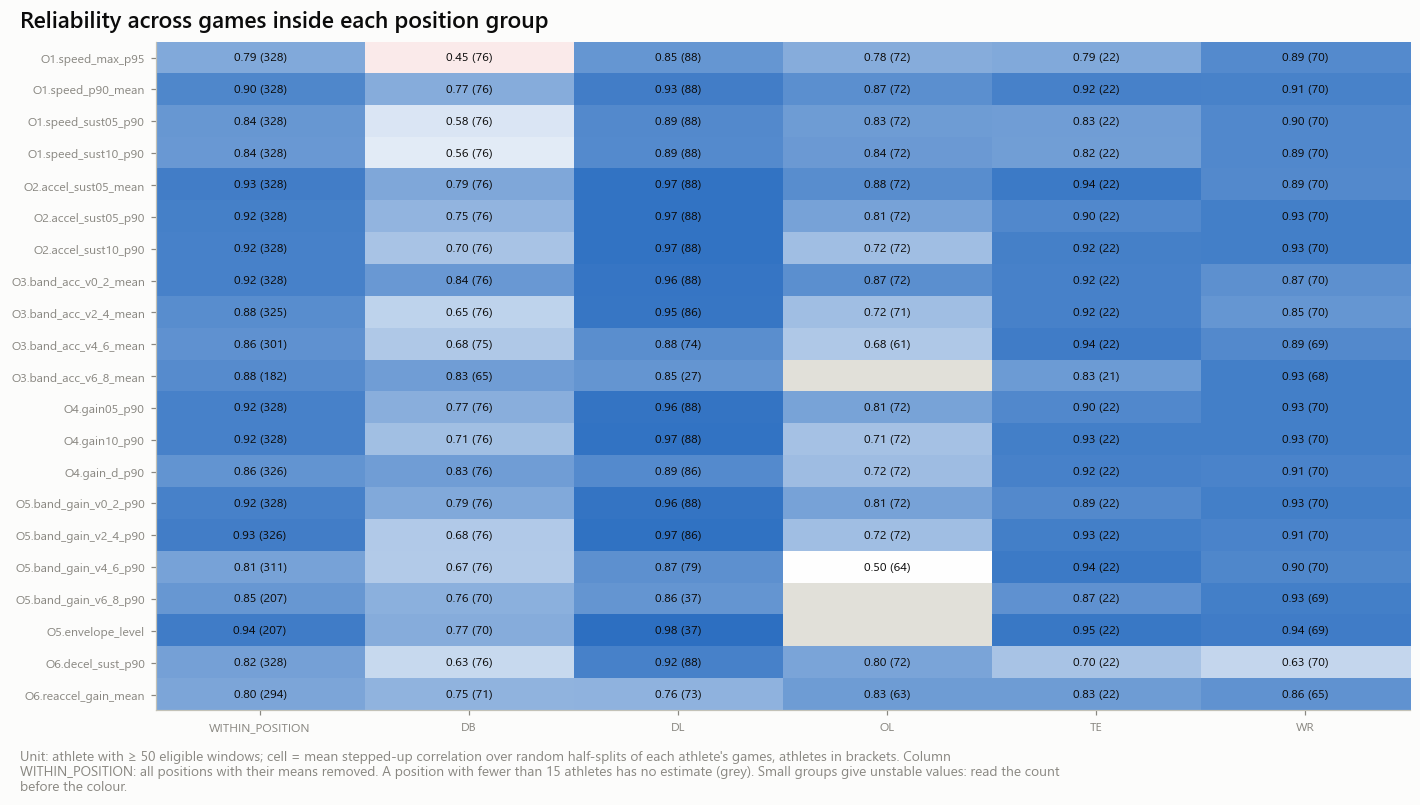

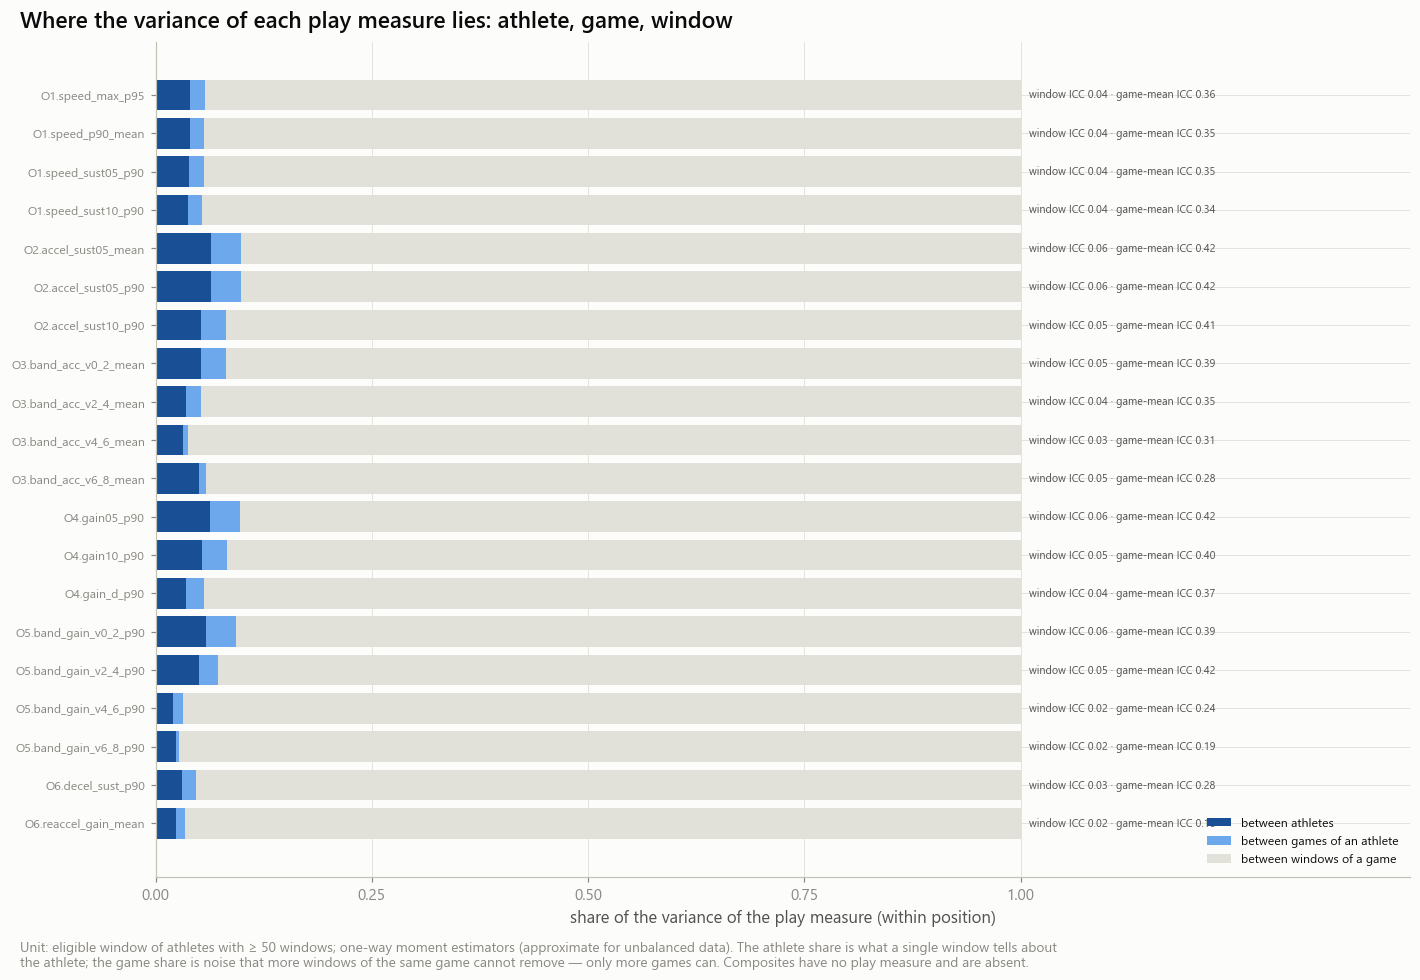

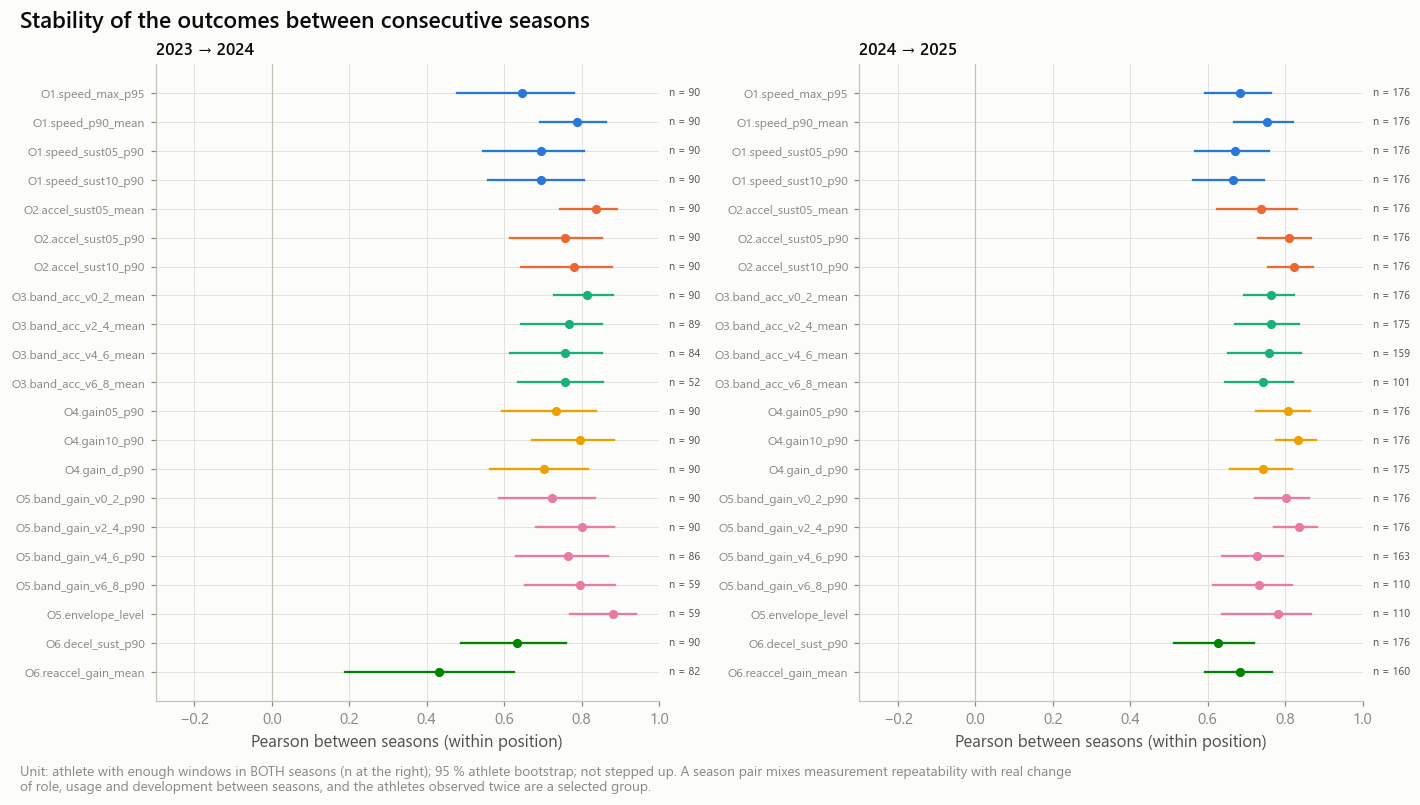

In [6]:
seasons = reliability.filter(pl.col('method').str.starts_with('season_') & (pl.col('adjustment') == 'raw'))
display(Markdown('**Stability between consecutive seasons** (unit: athlete observed in both seasons; not stepped up)'))
with pl.Config(tbl_rows=60, float_precision=3):
    display(seasons.select('outcome_id', 'method', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper', 'median_windows').sort('method', 'outcome_id'))
n_rel = int(at_thr['n_athletes'].max()) if at_thr.height else 0
store.show(nf.plot_reliability_by_position(reliability, c), 'AM05B_02_reliability_by_position_group',
           {'reliability': reliability.filter((pl.col('method') == 'game_random_halves_sb') & (pl.col('min_windows') == THR))},
           source='nfl_outcome_reliability', n=f'up to {n_rel} athletes')
store.show(nf.plot_variance_components(reliability, c), 'AM05B_04_variance_components', {'components': components},
           source='nfl_outcome_reliability', n=f'up to {n_rel} athletes')
store.show(nf.plot_season_stability(reliability, c), 'AM05B_10_season_stability', {'seasons': seasons}, source='nfl_outcome_reliability',
           n=f'up to {int(seasons["n_athletes"].max()) if seasons.height else 0} athletes')
FIGURES += ['AM05B_02_reliability_by_position_group', 'AM05B_04_variance_components', 'AM05B_10_season_stability']

## 5 · Reliability against exposure

High reliability on all available windows does not show that the first 20 windows are enough. The exposure table computes each outcome on an athlete's first N windows (20, 50, 100, 200) and first G games, in time order, and compares it with the same outcome on the games played strictly afterwards. Two cohorts are reported: `available` (every athlete who has the budget — more athletes at small budgets) and `common` (the same athletes at every budget, so the curve is not driven by who is left).

11:06:17 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_EXPOSURE] restored from cache (current)


**First windows against later games** (unit: athlete; Pearson within position; budget 0 = all available)

cohort `available` — estimate, then athletes

outcome_id,20,50,100,200
str,f64,f64,f64,f64
"""O1.speed_p90_mean""",0.597,0.723,0.782,0.790
"""O1.speed_sust05_p90""",0.437,0.600,0.656,0.736
"""O1.speed_sust10_p90""",0.437,0.602,0.660,0.734
"""O2.accel_sust05_mean""",0.679,0.750,0.781,0.779
"""O2.accel_sust05_p90""",0.607,0.680,0.771,0.797
"""O2.accel_sust10_p90""",0.599,0.700,0.786,0.810
"""O3.band_acc_v0_2_mean""",0.659,0.751,0.793,0.789
"""O3.band_acc_v2_4_mean""",0.589,0.685,0.771,0.811
"""O3.band_acc_v4_6_mean""",0.531,0.656,0.761,0.823


outcome_id,20,50,100,200
str,i64,i64,i64,i64
"""O1.speed_p90_mean""",319,300,283,237
"""O1.speed_sust05_p90""",319,300,283,237
"""O1.speed_sust10_p90""",319,300,283,237
"""O2.accel_sust05_mean""",319,300,283,237
"""O2.accel_sust05_p90""",319,300,283,237
"""O2.accel_sust10_p90""",319,300,283,237
"""O3.band_acc_v0_2_mean""",318,299,280,235
"""O3.band_acc_v2_4_mean""",309,298,273,225
"""O3.band_acc_v4_6_mean""",279,244,212,146


...

cohort `common` — estimate, then athletes

outcome_id,2,4,8,16
str,f64,f64,f64,f64
"""O1.speed_p90_mean""",0.528,0.686,0.800,0.814
"""O1.speed_sust05_p90""",0.412,0.663,0.744,0.737
"""O1.speed_sust10_p90""",0.399,0.651,0.737,0.735
"""O2.accel_sust05_mean""",0.663,0.759,0.784,0.772
"""O2.accel_sust05_p90""",0.574,0.699,0.760,0.749
"""O2.accel_sust10_p90""",0.644,0.750,0.780,0.788
"""O3.band_acc_v0_2_mean""",0.603,0.720,0.770,0.745
"""O3.band_acc_v2_4_mean""",0.588,0.681,0.778,0.821
"""O3.band_acc_v4_6_mean""",0.568,0.672,0.759,0.793


outcome_id,2,4,8,16
str,i64,i64,i64,i64
"""O1.speed_p90_mean""",170,170,170,170
"""O1.speed_sust05_p90""",170,170,170,170
"""O1.speed_sust10_p90""",170,170,170,170
"""O2.accel_sust05_mean""",170,170,170,170
"""O2.accel_sust05_p90""",170,170,170,170
"""O2.accel_sust10_p90""",170,170,170,170
"""O3.band_acc_v0_2_mean""",169,169,169,169
"""O3.band_acc_v2_4_mean""",166,166,166,166
"""O3.band_acc_v4_6_mean""",144,144,144,144


**Reliability of the first-N value itself and the variance-component projection** (windows budget)

outcome_id,method,budget,n_athletes,estimate,ci_lower,ci_upper
str,str,i64,i64,f64,f64,f64
"""O1.speed_p90_mean""","""game_random_halves_sb""",0,328,0.900,0.879,0.922
"""O1.speed_p90_mean""","""model_projection""",20,0,0.380,null,null
"""O1.speed_p90_mean""","""model_projection""",50,0,0.581,null,null
"""O1.speed_p90_mean""","""model_projection""",100,0,0.735,null,null
"""O1.speed_p90_mean""","""model_projection""",200,0,0.847,null,null
"""O1.speed_p90_mean""","""within_budget_game_split_sb""",20,172,0.472,0.269,0.626
"""O1.speed_p90_mean""","""within_budget_game_split_sb""",50,261,0.705,0.621,0.775
"""O1.speed_p90_mean""","""within_budget_game_split_sb""",100,300,0.772,0.712,0.823
"""O1.speed_p90_mean""","""within_budget_game_split_sb""",200,264,0.869,0.823,0.905


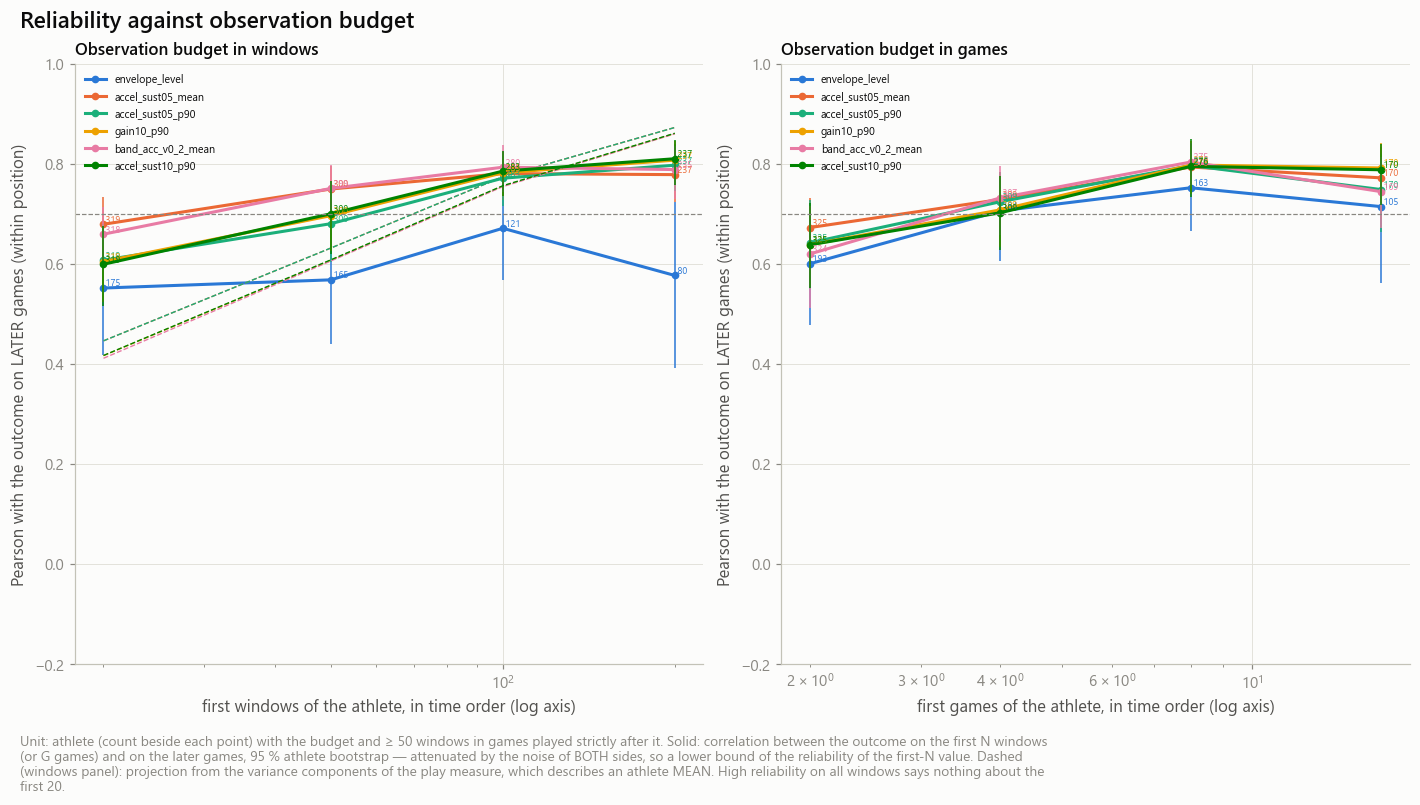

In [7]:
exposure = store.build('NFL_EXPOSURE', [orl.EXPOSURE], lambda: {orl.EXPOSURE.name: orl.exposure_table(eng, c, reliability)},
                       params=c.params(), files=[*PLAY_FILES, store.parquet(orl.RELIABILITY)])[orl.EXPOSURE.name]
candidates = dictionary.filter(pl.col('role') == 'candidate')['outcome_id'].to_list()
for kind in ('windows', 'games'):
    e = exposure.filter((pl.col('budget_type') == kind) & (pl.col('method') == 'first_vs_later_games') & pl.col('outcome_id').is_in(candidates))
    display(Markdown(f'**First {kind} against later games** (unit: athlete; Pearson within position; budget 0 = all available)'))
    with pl.Config(tbl_rows=60, float_precision=3):
        for cohort_name in ('available', 'common'):
            sub = e.filter(pl.col('cohort') == cohort_name)
            if sub.height:
                display(Markdown(f'cohort `{cohort_name}` — estimate, then athletes'))
                display(sub.pivot(on='budget', index='outcome_id', values='estimate').sort('outcome_id'))
                display(sub.pivot(on='budget', index='outcome_id', values='n_athletes').sort('outcome_id'))
display(Markdown('**Reliability of the first-N value itself and the variance-component projection** (windows budget)'))
inside = exposure.filter((pl.col('budget_type') == 'windows') & pl.col('method').is_in(['within_budget_game_split_sb', 'model_projection', 'game_random_halves_sb'])
                         & pl.col('outcome_id').is_in(candidates))
with pl.Config(tbl_rows=80, float_precision=3):
    display(inside.select('outcome_id', 'method', 'budget', 'n_athletes', 'estimate', 'ci_lower', 'ci_upper').sort('outcome_id', 'method', 'budget'))
ranked = (at_thr.filter((pl.col('method') == 'game_random_halves_sb') & (pl.col('adjustment') == 'raw') & pl.col('outcome_id').is_in(candidates))
          .sort('estimate', descending=True, nulls_last=True))
CURVE_IDS = ranked['outcome_id'].head(6).to_list()
store.show(nf.plot_exposure_curves(exposure, CURVE_IDS, c), 'AM05B_03_reliability_vs_exposure', {'exposure': exposure}, publication=True,
           source='nfl_reliability_vs_exposure', n=f'up to {n_rel} athletes',
           note='the six candidates with the highest all-games reliability are drawn; the table holds every outcome')
FIGURES += ['AM05B_03_reliability_vs_exposure']

## 6 · Context

How much of each play measure follows an observed context label inside a position group, and what the context adjustment changes at athlete level. Only alignment, play class, side and down are available. A small share does not show that context is controlled: assignment, opponent and scheme are unobserved. A large share with a reliability that survives the adjustment says the outcome is not *only* alignment mix; a reliability that collapses after adjustment says it mostly was.

11:06:20 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_CONTEXT] restored from cache (current)


**Largest share of the play-measure variance explained by a context variable, over position groups** (unit: eligible window)

outcome_id,lined_up_position,context_cell,side,down,play_class
str,f64,f64,f64,f64,f64
"""O1.speed_max_p95""",0.084,0.184,0.083,0.085,0.131
"""O1.speed_p90_mean""",0.082,0.173,0.081,0.083,0.125
"""O1.speed_sust05_p90""",0.083,0.181,0.082,0.085,0.130
"""O1.speed_sust10_p90""",0.081,0.175,0.080,0.082,0.130
"""O2.accel_sust05_mean""",0.130,0.338,0.033,0.039,0.211
"""O2.accel_sust05_p90""",0.130,0.338,0.033,0.039,0.211
"""O2.accel_sust10_p90""",0.112,0.309,0.052,0.057,0.198
"""O3.band_acc_v0_2_mean""",0.093,0.221,0.030,0.031,0.129
"""O3.band_acc_v2_4_mean""",0.082,0.107,0.063,0.065,0.063


**What the context adjustment changes at athlete level** (unit: athlete with ≥ 50 windows)

outcome_id,position_group,n_athletes,pearson_raw_vs_adjusted,sd_of_change_over_sd_raw
str,str,i64,f64,f64
"""O1.speed_max_p95""","""DB""",78,0.811,0.605
"""O1.speed_max_p95""","""DL""",88,0.733,0.682
"""O1.speed_max_p95""","""OL""",77,0.982,0.192
"""O1.speed_max_p95""","""TE""",23,0.973,0.261
"""O1.speed_max_p95""","""WR""",70,0.990,0.144
"""O1.speed_p90_mean""","""DB""",78,0.740,0.678
"""O1.speed_p90_mean""","""DL""",88,0.665,0.762
"""O1.speed_p90_mean""","""OL""",77,0.983,0.182
"""O1.speed_p90_mean""","""TE""",23,0.983,0.197


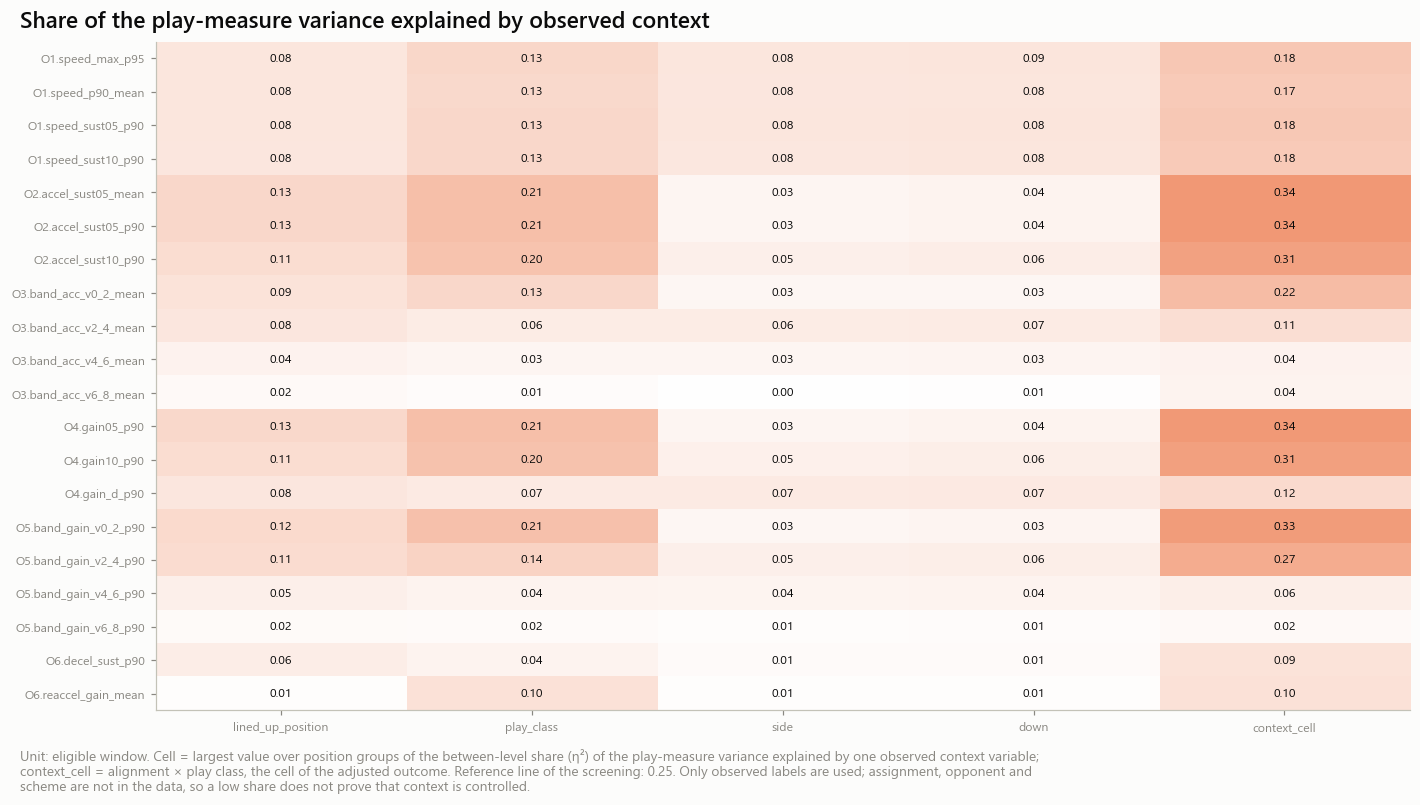

In [8]:
context = store.build('NFL_CONTEXT', [orl.CONTEXT], lambda: {orl.CONTEXT.name: orl.context_audit(eng, outcomes, c)},
                      params=c.params(), files=[*PLAY_FILES, store.parquet(no.ATHLETE_OUTCOMES)])[orl.CONTEXT.name]
eta = (context.filter((pl.col('level') == '__ALL__') & pl.col('eta2').is_not_null()).group_by('outcome_id', 'variable')
       .agg(pl.col('eta2').max()).pivot(on='variable', index='outcome_id', values='eta2').sort('outcome_id'))
display(Markdown('**Largest share of the play-measure variance explained by a context variable, over position groups** (unit: eligible window)'))
with pl.Config(tbl_rows=40, float_precision=3):
    display(eta)
adjust = (context.filter(pl.col('variable') == 'athlete_adjustment')
          .select('outcome_id', 'position_group', 'n_athletes', pl.col('mean').alias('pearson_raw_vs_adjusted'), pl.col('sd').alias('sd_of_change_over_sd_raw'))
          .sort('outcome_id', 'position_group'))
display(Markdown(f'**What the context adjustment changes at athlete level** (unit: athlete with ≥ {THR} windows)'))
with pl.Config(tbl_rows=120, float_precision=3):
    display(adjust)
store.show(nf.plot_context(context, c), 'AM05B_05_context_share', {'eta2': eta}, source='nfl_outcome_context_audit',
           n=f'{eng.plays.height} windows, {eng.athletes.height} athletes')
FIGURES += ['AM05B_05_context_share']

## 7 · Smoothing, boundary and quality sensitivity

Athlete-level agreement between the primary definition and each alternative, on the same windows: three other Savitzky–Golay filters, the boundary-inclusive variant, and four quality filters (tier A only, athlete listed in the player-play record, at least 3 s of post-snap frames, at most 20 % boundary frames). Reported: within-position Pearson and Spearman, the mean shift in the unit of the outcome and in SD units, and the game-split reliability of both definitions on the same athletes.

11:06:23 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_SENSITIVITY] restored from cache (current)


**Rank agreement with the primary definition** (unit: athlete; Spearman within position)

outcome_id,boundary_incl,sg11p3,sg5p2,sg9p2,tier_A_only,in_player_play_only,post_snap_ge_3s,boundary_frac_le_0p2
str,f64,f64,f64,f64,f64,f64,f64,f64
"""O1.speed_max_p95""",1.000,0.999,0.999,0.999,0.966,0.999,0.999,1.000
"""O1.speed_p90_mean""",1.000,1.000,1.000,1.000,0.994,0.996,0.978,1.000
"""O1.speed_sust05_p90""",0.999,0.998,1.000,0.999,0.980,0.999,0.998,1.000
"""O1.speed_sust10_p90""",1.000,0.998,1.000,0.999,0.978,0.999,0.998,1.000
"""O2.accel_sust05_mean""",1.000,0.995,0.999,0.999,0.999,0.998,0.986,1.000
"""O2.accel_sust05_p90""",1.000,0.983,0.993,0.995,0.998,0.999,0.999,1.000
"""O2.accel_sust10_p90""",1.000,0.990,0.996,0.996,0.996,0.999,1.000,1.000
"""O3.band_acc_v0_2_mean""",0.996,0.996,0.999,0.998,0.998,0.998,0.993,1.000
"""O3.band_acc_v2_4_mean""",0.995,0.995,0.996,0.997,0.999,0.995,1.000,1.000


**Level shift and reliability under each variant** (unit: athlete; shift = variant − primary)

outcome_id,variant,kind,n_athletes,mean_shift,shift_sd_units,sd_ratio,reliability_primary,reliability_variant,windows_retained
str,str,str,i64,f64,f64,f64,f64,f64,f64
"""O1.speed_max_p95""","""boundary_incl""","""boundary""",344,0.000,0.000,1.000,0.673,0.673,1.000
"""O1.speed_max_p95""","""boundary_frac_le_0p2""","""quality_filter""",336,0.000,0.000,1.000,0.767,0.767,1.000
"""O1.speed_max_p95""","""in_player_play_only""","""quality_filter""",336,0.006,0.004,1.004,0.767,0.765,0.991
"""O1.speed_max_p95""","""post_snap_ge_3s""","""quality_filter""",336,0.012,0.009,0.996,0.767,0.785,0.986
"""O1.speed_max_p95""","""tier_A_only""","""quality_filter""",336,-0.039,-0.027,1.021,0.767,0.739,0.992
"""O1.speed_max_p95""","""sg11p3""","""smoothing""",344,0.043,0.030,1.000,0.673,0.676,1.000
"""O1.speed_max_p95""","""sg5p2""","""smoothing""",344,0.029,0.020,1.000,0.673,0.674,1.000
"""O1.speed_max_p95""","""sg9p2""","""smoothing""",344,-0.029,-0.020,1.000,0.673,0.670,1.000
"""O1.speed_p90_mean""","""boundary_incl""","""boundary""",344,0.000,0.000,1.000,0.807,0.807,1.000


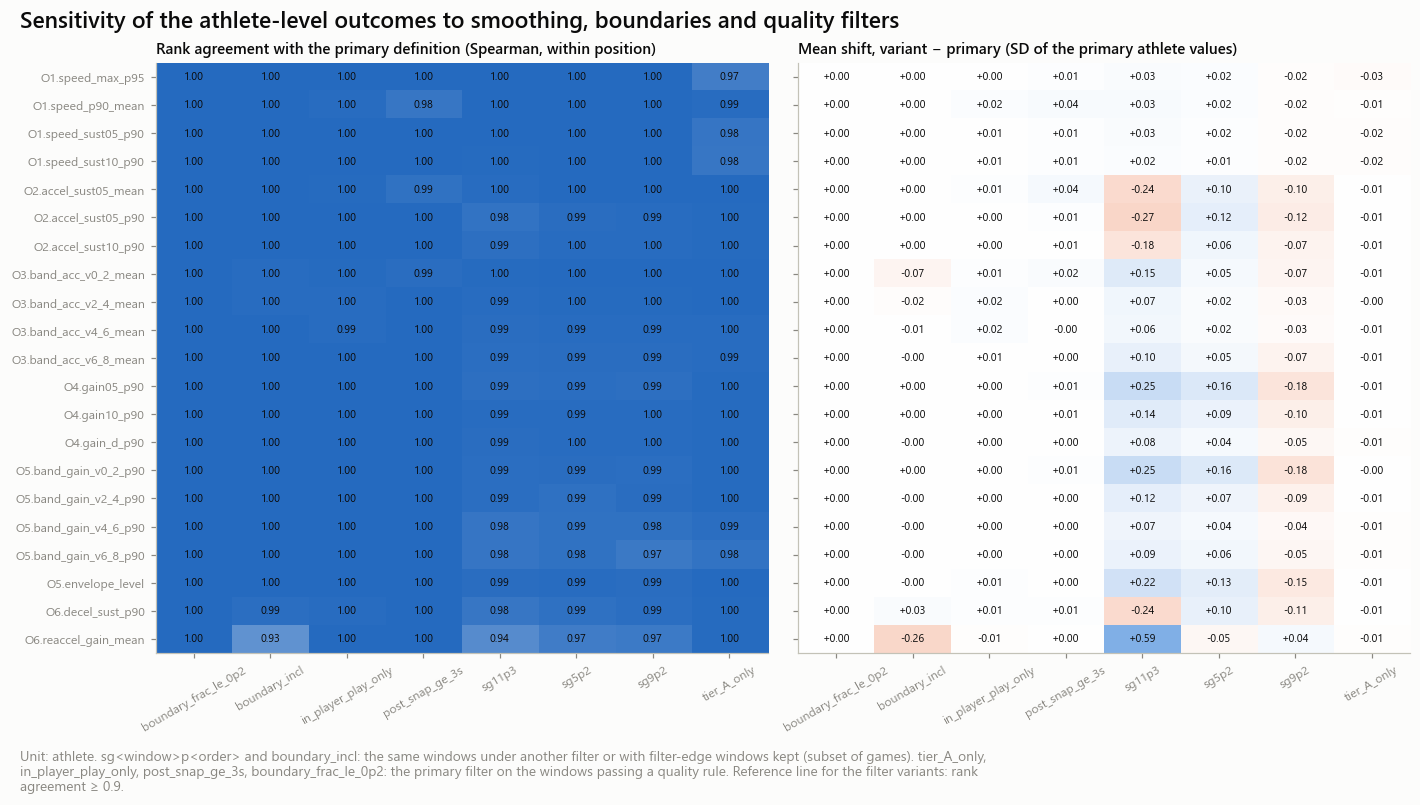

In [9]:
sensitivity = store.build('NFL_SENSITIVITY', [orl.SENSITIVITY], lambda: {orl.SENSITIVITY.name: orl.sensitivity_table(eng, plays, variants, c)},
                          params=c.params(), files=PLAY_FILES)[orl.SENSITIVITY.name]
display(Markdown('**Rank agreement with the primary definition** (unit: athlete; Spearman within position)'))
with pl.Config(tbl_rows=40, float_precision=3):
    display(sensitivity.pivot(on='variant', index='outcome_id', values='spearman').sort('outcome_id'))
display(Markdown('**Level shift and reliability under each variant** (unit: athlete; shift = variant − primary)'))
with pl.Config(tbl_rows=200, float_precision=3):
    display(sensitivity.select('outcome_id', 'variant', 'kind', 'n_athletes', 'mean_shift', 'shift_sd_units', 'sd_ratio', 'reliability_primary',
                               'reliability_variant', 'windows_retained').sort('outcome_id', 'kind', 'variant'))
store.show(nf.plot_sensitivity(sensitivity, c), 'AM05B_06_outcome_sensitivity', {'sensitivity': sensitivity}, publication=True,
           source='nfl_outcome_quality_sensitivity', n=f'up to {int(sensitivity["n_athletes"].max()) if sensitivity.height else 0} athletes')
FIGURES += ['AM05B_06_outcome_sensitivity']

## 8 · Redundancy between outcomes

Several candidates measure nearly the same thing by construction (a 0.5 s mean acceleration and a 0.5 s speed gain; the 0.5 s and 1.0 s versions of a measure). Two outcomes that rank athletes almost identically are one target, not two.

11:06:28 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_REDUNDANCY] restored from cache (current)


**Outcome pairs with |Spearman| ≥ 0.9 within position** (unit: athlete with ≥ 50 windows on both)

outcome_a,outcome_b,n_athletes,spearman
str,str,i64,f64
"""O2.accel_sust05_p90""","""O4.gain05_p90""",336,0.997
"""O4.gain05_p90""","""O5.band_gain_v0_2_p90""",336,0.996
"""O1.speed_sust05_p90""","""O1.speed_sust10_p90""",336,0.996
"""O2.accel_sust10_p90""","""O4.gain10_p90""",336,0.994
"""O2.accel_sust05_p90""","""O5.band_gain_v0_2_p90""",336,0.994
"""O4.gain10_p90""","""O5.band_gain_v2_4_p90""",334,0.967
"""O2.accel_sust10_p90""","""O5.band_gain_v2_4_p90""",334,0.965
"""O2.accel_sust05_p90""","""O4.gain10_p90""",336,0.954
"""O4.gain05_p90""","""O4.gain10_p90""",336,0.947


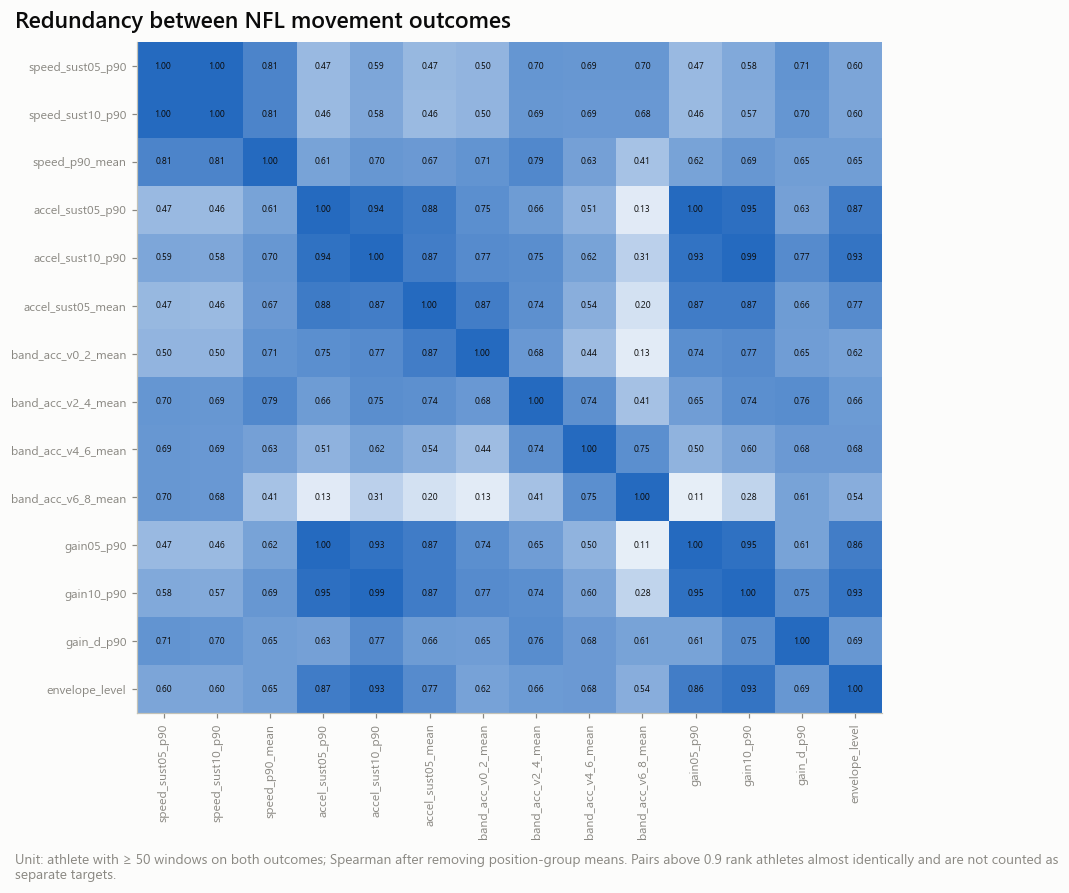

In [10]:
redundancy = store.build('NFL_REDUNDANCY', [orl.REDUNDANCY], lambda: {orl.REDUNDANCY.name: orl.redundancy_table(outcomes, c)},
                         params=c.params(), files=[store.parquet(no.ATHLETE_OUTCOMES)])[orl.REDUNDANCY.name]
display(Markdown(f'**Outcome pairs with |Spearman| ≥ {c.ref_redundancy:g} within position** (unit: athlete with ≥ {THR} windows on both)'))
with pl.Config(tbl_rows=80, float_precision=3):
    display(redundancy.filter(pl.col('spearman').abs() >= c.ref_redundancy).sort('spearman', descending=True))
store.show(nf.plot_redundancy(redundancy, candidates, c), 'AM05B_07_outcome_redundancy', {'redundancy': redundancy},
           source='nfl_outcome_redundancy', n=f'up to {int(redundancy["n_athletes"].max()) if redundancy.height else 0} athletes')
FIGURES += ['AM05B_07_outcome_redundancy']

## 9 · Screening and rule-based proposal

One row per outcome with the evidence and five reference lines: coverage (athletes at the threshold, position groups with enough athletes), reliability (random game halves and the lower bound of the odd / even interval), smoothing (smallest rank agreement over the filter and boundary variants), exposure dependence (rank correlation of the value with log window count) and context (largest context-cell share, or a context-adjusted reliability above the line).

The lines are heuristics. The label is `eligible` when all five are met and `provisional` when coverage and reliability are met. Reference, component and exploratory outcomes keep their role whatever their numbers. The proposal takes the eligible candidate with the highest lower reliability bound, then at most two secondaries from other families that are not near copies of a chosen target. If no candidate is eligible the proposal is `STOP`.

11:06:30 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:NFL_SCREEN] restored from cache (current)


**Screening table** (unit: outcome; reference lines are heuristics, labels are for review)

outcome_id,role,status,n_athletes,n_positions,reliability,reliability_lower,reliability_upper,reliability_adj,reliability_min_position,first_n_r,smoothing_min_spearman,max_shift_sd,exposure_rho,context_eta2,n_passed
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""O5.band_gain_v0_2_p90""","""component""","""component""",336,5,0.920,0.904,0.953,0.818,0.787,0.676,0.991,0.253,0.118,0.326,5
"""O5.band_gain_v2_4_p90""","""component""","""component""",334,5,0.930,0.903,0.944,0.787,0.677,0.720,0.986,0.124,0.106,0.274,5
"""O5.band_gain_v4_6_p90""","""component""","""component""",312,5,0.809,0.767,0.861,0.726,0.501,0.575,0.980,0.072,0.083,0.056,5
"""O5.band_gain_v6_8_p90""","""component""","""component""",207,4,0.847,0.791,0.898,0.827,0.764,0.651,0.974,0.089,0.126,0.021,5
"""O1.speed_p90_mean""","""candidate""","""eligible""",336,5,0.900,0.891,0.938,0.858,0.775,0.723,1.000,0.032,-0.086,0.173,5
"""O1.speed_sust05_p90""","""candidate""","""eligible""",336,5,0.844,0.796,0.888,0.753,0.583,0.600,0.998,0.026,-0.085,0.181,5
"""O1.speed_sust10_p90""","""candidate""","""eligible""",336,5,0.840,0.796,0.888,0.749,0.563,0.602,0.998,0.021,-0.090,0.175,5
"""O2.accel_sust05_mean""","""candidate""","""eligible""",336,5,0.932,0.936,0.960,0.843,0.792,0.750,0.995,0.238,0.110,0.338,5
"""O2.accel_sust05_p90""","""candidate""","""eligible""",336,5,0.923,0.910,0.954,0.818,0.749,0.680,0.983,0.272,0.126,0.338,5


**Reference lines not met**

outcome_id,status,reasons
str,str,str


**Rule-based proposal: FREEZE** — primary `O2.accel_sust05_mean`, secondary ['O5.envelope_level', 'O3.band_acc_v0_2_mean']. highest lower reliability bound among eligible candidates; secondaries from other families with |Spearman| < 0.9 to every chosen target.

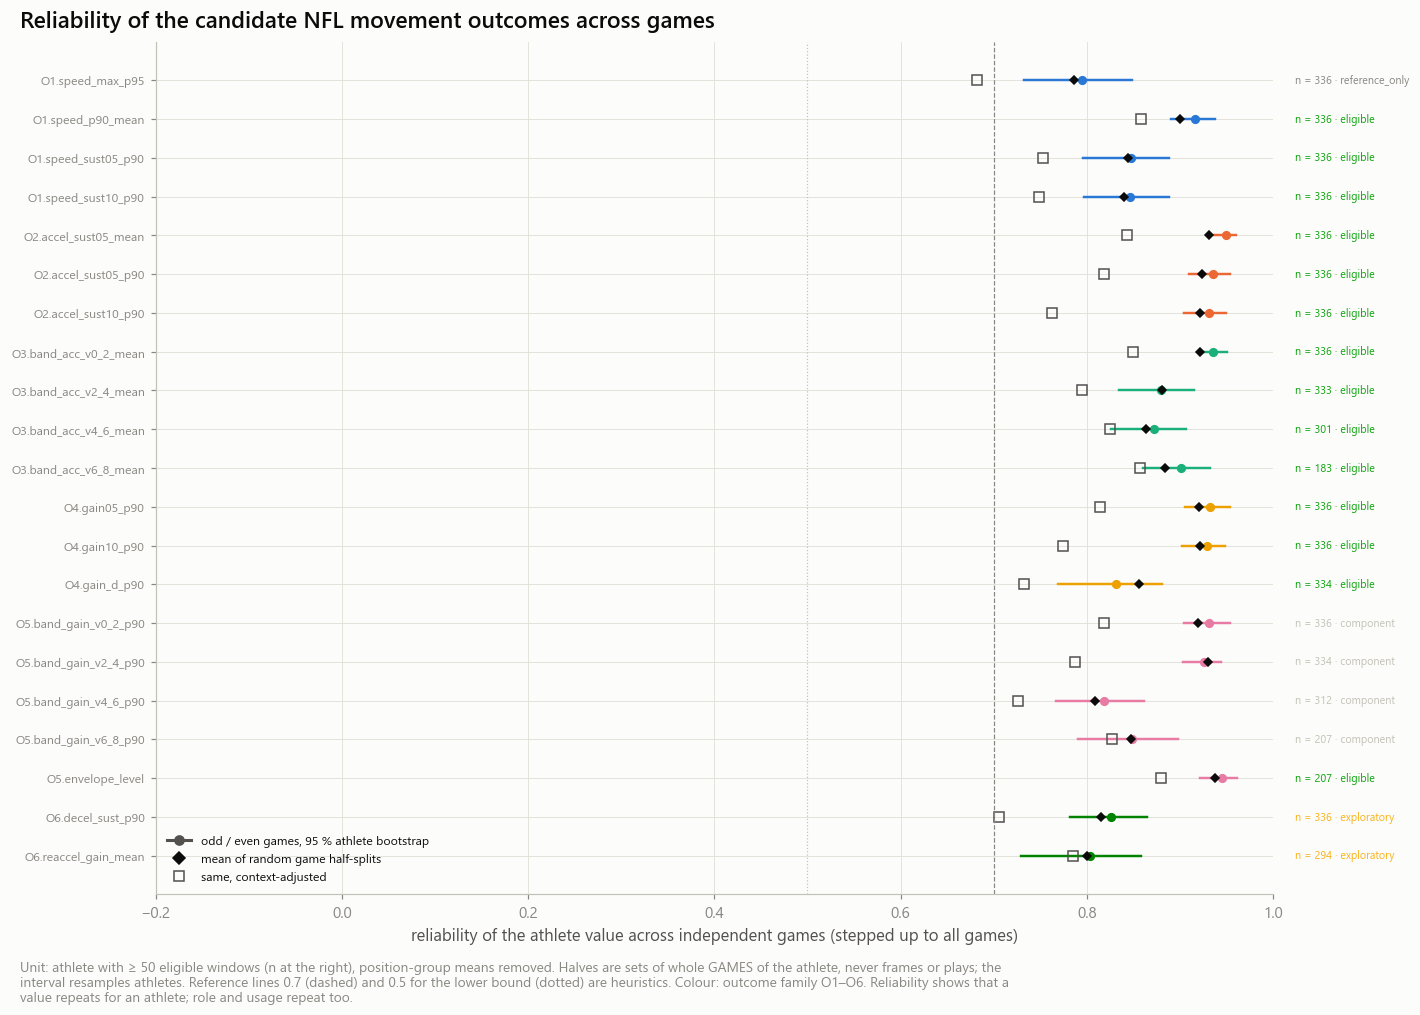

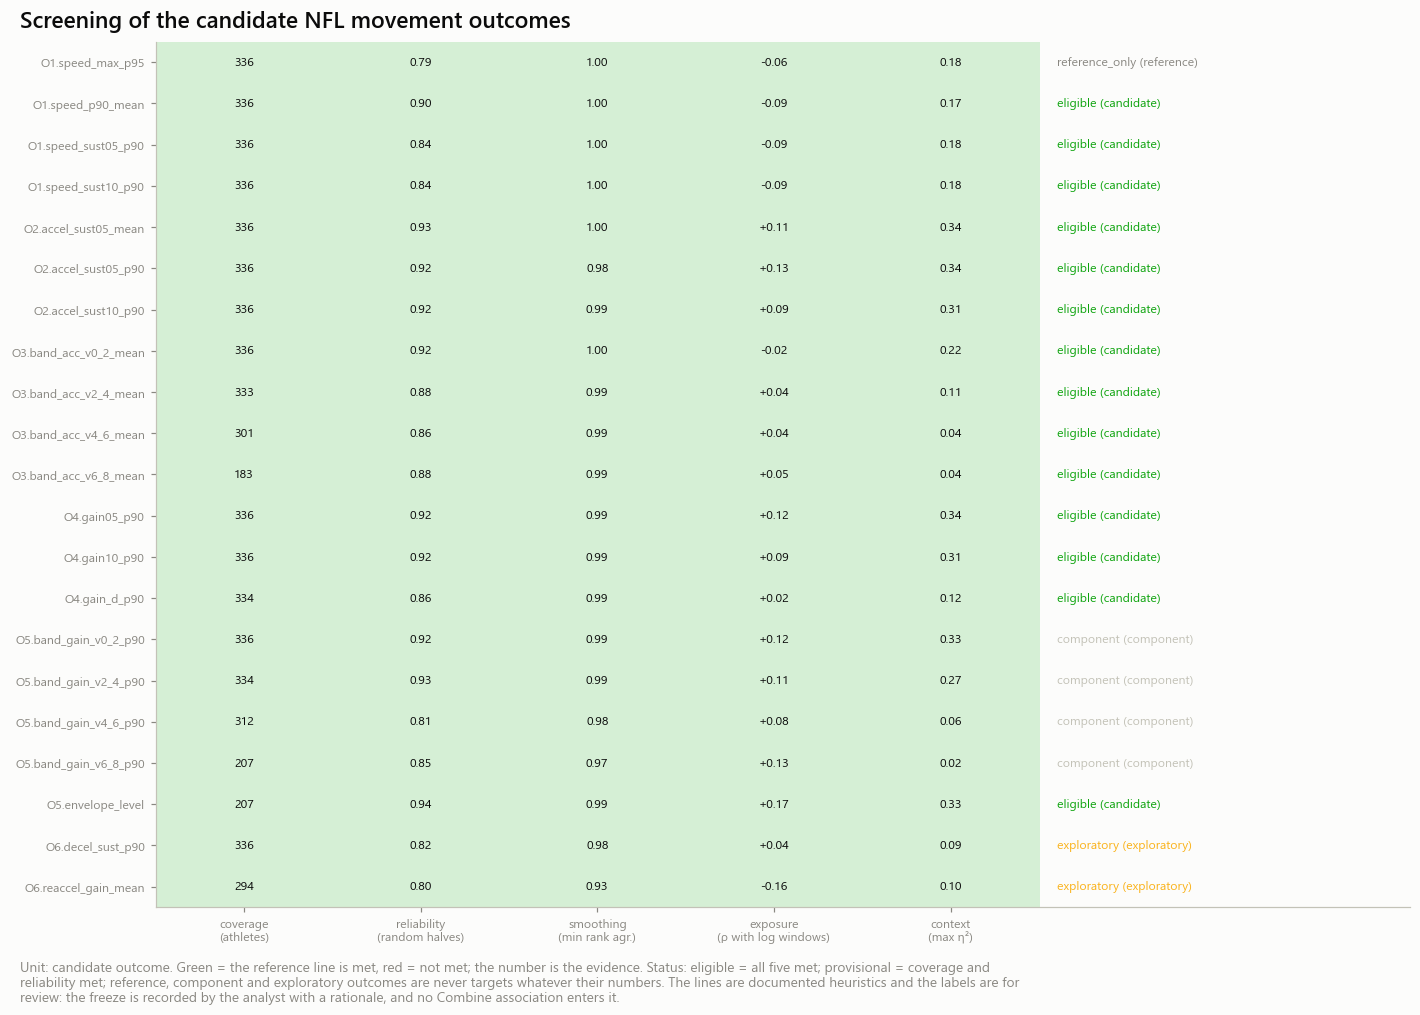

In [11]:
SCREEN_FILES = [store.parquet(t) for t in (COVERAGE, orl.RELIABILITY, orl.EXPOSURE, orl.SENSITIVITY, orl.CONTEXT)]
screen = store.build('NFL_SCREEN', [orl.SCREEN],
                     lambda: {orl.SCREEN.name: orl.screen_table(eng.specs, coverage, reliability, exposure, sensitivity, context, c)},
                     params=c.params(), files=SCREEN_FILES)[orl.SCREEN.name]
proposal = orl.propose_targets(screen, redundancy, c)
display(Markdown('**Screening table** (unit: outcome; reference lines are heuristics, labels are for review)'))
with pl.Config(tbl_rows=40, float_precision=3, fmt_str_lengths=60):
    display(screen.select('outcome_id', 'role', 'status', 'n_athletes', 'n_positions', 'reliability', 'reliability_lower', 'reliability_upper',
                          'reliability_adj', 'reliability_min_position', 'first_n_r', 'smoothing_min_spearman', 'max_shift_sd', 'exposure_rho',
                          'context_eta2', 'n_passed').sort('status', 'outcome_id'))
display(Markdown('**Reference lines not met**'))
with pl.Config(tbl_rows=40, fmt_str_lengths=400, tbl_width_chars=220):
    display(screen.filter(pl.col('reasons') != '').select('outcome_id', 'status', 'reasons').sort('outcome_id'))
prop_primary, prop_secondary, prop_reason = proposal['primary'], proposal['secondary'], proposal['reason']
display(Markdown(f'**Rule-based proposal: {proposal["decision"]}** — primary `{prop_primary}`, secondary {prop_secondary}. {prop_reason}.'))
store.show(nf.plot_reliability_forest(reliability, screen, c), 'AM05B_01_reliability_across_games',
           {'reliability': at_thr, 'screen': screen.drop('reasons')}, publication=True, source='nfl_outcome_reliability, nfl_outcome_screen',
           n=f'up to {n_rel} athletes')
store.show(nf.plot_screen(screen, c), 'AM05B_08_outcome_screen', {'screen': screen.drop('reasons')}, publication=True,
           source='nfl_outcome_screen', n=f'{screen.height} outcomes')
FIGURES += ['AM05B_01_reliability_across_games', 'AM05B_08_outcome_screen']

## 10 · Freeze decision

**Set this after reviewing the FULL run.** Leave `DECISION = None` until then: nothing is written while the decision is pending.

- `DECISION = 'FREEZE'` with `PRIMARY` (one outcome) and `SECONDARY` (at most two). A target must be a candidate labelled `eligible`, or `provisional` with a written `RATIONALE`. Selection criteria: physical interpretability, reliability, measured coverage, stability across games, adequacy of context control, position-specific relevance, reproducibility, measurement quality.
- `DECISION = 'STOP'` when no outcome is reliable and interpretable enough. The outcome definitions are then revised before any transfer model; no score is built on an unreliable target.

The artifact `nfl_movement_targets_v1.json` is written once per run mode. A later run that would produce a different freeze keeps the existing file and says so; `REFREEZE_TARGETS = True` replaces it and should only be used before any transfer analysis has read it. **Do not look at a Combine correlation before this cell is final.**

In [13]:
DECISION = "FREEZE"      # None = pending review · 'FREEZE' · 'STOP'
PRIMARY = None       # outcome_id of the primary target, e.g. the rule-based proposal after review
SECONDARY = []       # at most two outcome_ids
RATIONALE = ''       # why these targets (required for a provisional outcome and for any departure from the proposal)

# ── Milestone 05B — Research target freeze ──

DECISION = "FREEZE"

# Primary: sustained NFL acceleration (0.5 s)
PRIMARY = "O2.accel_sust05_mean"

# Secondary: low-speed acceleration + robust NFL speed
SECONDARY = [
    "O3.band_acc_v0_2_mean",
    "O1.speed_p90_mean",
]

RATIONALE = (
    "Primary O2 is a physically interpretable sustained-acceleration outcome "
    "with strong across-game reliability and broad athlete coverage. "
    "O3 evaluates acceleration conditional on low starting speed, "
    "while O1 provides a robust realized-speed control. "
    "These targets were selected using measurement reliability, coverage, "
    "physical interpretation and context diagnostics, without examining "
    "their associations with Combine features. "
    "The movement envelope O5 remains exploratory because of lower coverage."
)

REFREEZE_TARGETS = False

provenance = {'notebook': NB05B, 'play_table_notebook': NB05A, 'definition_hash': no.definition_hash(c), 'seed': controls.seed,
              'run_mode': controls.run_mode, 'n_athletes': eng.athletes.height, 'n_eligible_windows': eng.plays.height,
              'inputs': {cfg.paths.rel(f): (file_fingerprint(f) if f.is_file() else 'missing') for f in [*PLAY_FILES, *SCREEN_FILES]},
              'source_tables': upstream.get('inputs', {})}
frozen, freeze_message = orl.freeze_targets(store, DECISION, PRIMARY, SECONDARY, RATIONALE, proposal, screen, dictionary, coverage, c,
                                            provenance, refreeze=REFREEZE_TARGETS)
gate_status, gate_sentence = orl.gate_05(frozen)
display(Markdown(f'**Freeze: {freeze_message}**\n\n**Research gate 05: {gate_status}** — {gate_sentence}.'))
if controls.smoke and frozen:
    display(Markdown('**SMOKE RUN: this artifact is a wiring check under `_sample`; it is not a research decision.**'))
if frozen and frozen.get('targets'):
    rows = [{'rank': t['rank'], 'outcome_id': t['outcome_id'], 'units': t['units'], 'statistic': t['athlete_statistic'], 'window': t['window'],
             'context_adjustment': t['context_adjustment'], 'reliability': t['reliability']['estimate'],
             'ci_lower': t['reliability']['odd_even_ci_lower'], 'ci_upper': t['reliability']['odd_even_ci_upper'],
             'definition_hash': t['definition_hash']} for t in frozen['targets']]
    with pl.Config(fmt_str_lengths=80, float_precision=3):
        display(pl.DataFrame(rows))
    for t in frozen['targets']:
        rank, oid, formula, counts = t['rank'], t['outcome_id'], t['formula'], t['eligibility_counts']
        display(Markdown(f'**{rank}: `{oid}`** — {formula}'))
        display(pl.DataFrame(counts))

11:09:49 | INFO    | nflbdb.research.advanced_movement.outcome_reliability | [nfl_outcomes] nfl_movement_targets_v1.json written: decision FREEZE, targets ['O2.accel_sust05_mean', 'O3.band_acc_v0_2_mean', 'O1.speed_p90_mean']


**Freeze: frozen now**

**Research gate 05: PASS** — frozen without consulting Combine associations: O2.accel_sust05_mean, O3.band_acc_v0_2_mean, O1.speed_p90_mean.

rank,outcome_id,units,statistic,window,context_adjustment,reliability,ci_lower,ci_upper,definition_hash
str,str,str,str,str,str,f64,f64,f64,str
"""primary""","""O2.accel_sust05_mean""","""yd/s²""","""mean""","""0.5 s, post-snap""","""cell_residual""",0.932,0.936,0.960,"""8d2379a4ace038fe"""
"""secondary""","""O3.band_acc_v0_2_mean""","""yd/s²""","""mean""","""0.5 s, post-snap""","""none""",0.922,0.920,0.950,"""9db83447f033153e"""
"""secondary""","""O1.speed_p90_mean""","""yd/s""","""mean""","""whole post-snap window""","""none""",0.900,0.891,0.938,"""380f7c40ed7011a7"""


**primary: `O2.accel_sust05_mean`** — mean over eligible windows of max_t mean(a_tan[t, t + 0.5 s])

position_group,n_athletes_tracked,n_athletes_ge_50,n_windows,n_athlete_games
str,i64,i64,i64,i64
"""ALL""",401,336,241760,7891
"""DB""",96,78,63767,1744
"""DL""",98,88,50316,1953
"""OL""",91,77,82717,1640
"""TE""",33,23,8124,681
"""WR""",83,70,36836,1873


**secondary: `O3.band_acc_v0_2_mean`** — mean over eligible windows of mean_t [(speed(t + 0.5 s) − speed(t)) / 0.5 s] over start frames with speed in [0, 2) and a positive change (≥ 3 such frames)

position_group,n_athletes_tracked,n_athletes_ge_50,n_windows,n_athlete_games
str,i64,i64,i64,i64
"""ALL""",401,336,236756,7882
"""DB""",96,78,61307,1742
"""DL""",98,88,49931,1953
"""OL""",91,77,82437,1639
"""TE""",33,23,7848,680
"""WR""",83,70,35233,1868


**secondary: `O1.speed_p90_mean`** — mean over eligible windows of the 90th percentile of post-snap frame speeds

position_group,n_athletes_tracked,n_athletes_ge_50,n_windows,n_athlete_games
str,i64,i64,i64,i64
"""ALL""",401,336,242043,7891
"""DB""",96,78,63914,1744
"""DL""",98,88,50363,1953
"""OL""",91,77,82806,1640
"""TE""",33,23,8124,681
"""WR""",83,70,36836,1873


## 11 · Early exposure against later games for the focus outcome

The focus outcome is the frozen primary target when one exists, else the proposed primary, else the candidate with the highest reliability. Each athlete's value on the first windows is set against the same outcome on later games, both centred within position.

**Focus outcome `O2.accel_sust05_mean`**: 324 athletes have 50 windows and at least one later game

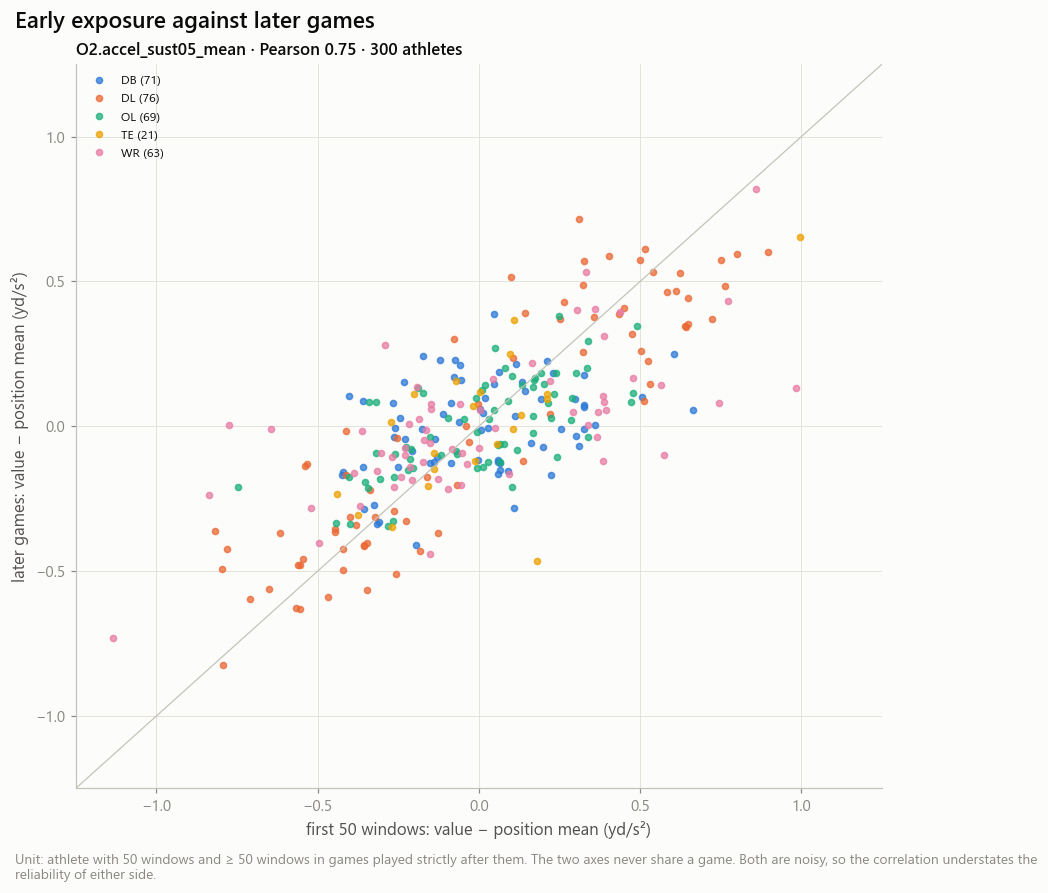

OSError: [Errno 22] Invalid argument: 'C:\\Users\\myben\\Downloads\\nfl-big-data-bowl-2027\\nfl-big-data-bowl-2027\\reports\\figures\\advanced_movement\\nfl_outcomes\\AM05B_09_first_windows_vs_later_games.png'

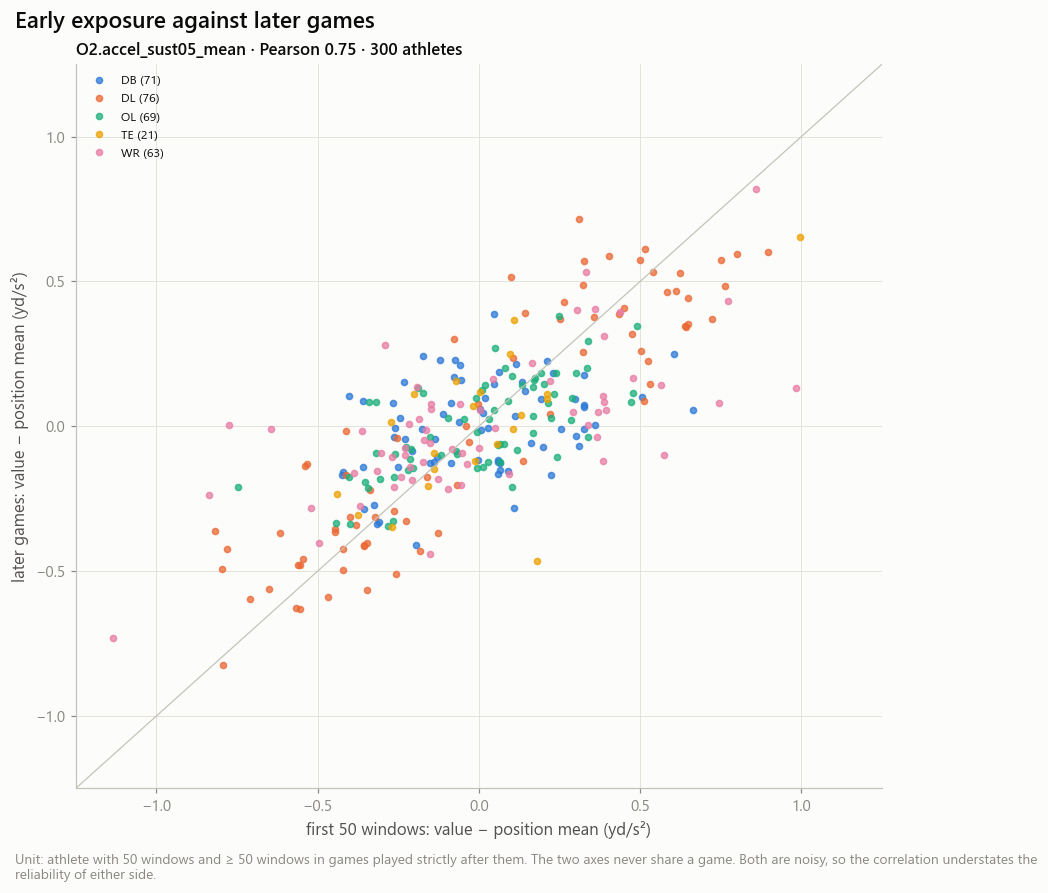

In [14]:
frozen_primary = frozen['targets'][0]['outcome_id'] if frozen and frozen.get('targets') else None
FOCUS = frozen_primary or proposal['primary'] or (CURVE_IDS[0] if CURVE_IDS else None)
if FOCUS is None:
    display(Markdown('**No candidate outcome has a reliability estimate at the primary threshold: nothing to draw.**'))
else:
    focus_unit = dictionary.filter(pl.col('outcome_id') == FOCUS)['unit'][0]
    focus_pairs = orl.budget_pairs(eng, eng.by_id[FOCUS], 'windows', THR)
    display(Markdown(f'**Focus outcome `{FOCUS}`**: {focus_pairs.height} athletes have {THR} windows and at least one later game'))
    store.show(nf.plot_first_vs_later(focus_pairs, FOCUS, THR, 'windows', focus_unit, c), 'AM05B_09_first_windows_vs_later_games',
               {'pairs': focus_pairs}, publication=True, source='nfl_play_movement', n=f'{focus_pairs.height} athletes')
    FIGURES += ['AM05B_09_first_windows_vs_later_games']

## 12 · Conclusions generated from the tables

Written from the tables of this run only. In smoke mode it is a wiring check.

In [ ]:
conclusions = orl.conclusions_markdown(screen, proposal, frozen, c)
if controls.smoke:
    conclusions = '**SMOKE RUN — technical check only. Do not interpret any number below.**\n\n' + conclusions
display(Markdown(conclusions))
manifest = {'notebook': NB05B, 'status': 'executed', 'definition_hash': no.definition_hash(c), 'config': c.params(), 'seed': controls.seed,
            'n_athletes': eng.athletes.height, 'n_eligible_windows': eng.plays.height, 'proposal': proposal, 'decision': DECISION,
            'gate_05': gate_status, 'freeze_message': freeze_message, 'focus_outcome': FOCUS, 'figures': FIGURES,
            'validation': validation_report.to_dicts()}
if controls.save_tables:
    store.write_json('nfl_reliability_manifest', manifest)
    (store.tables_dir / 'nfl_outcome_conclusions.md').write_text(conclusions, encoding='utf-8')
listing = []
for kind, folder, pattern in (('table (CSV)', store.tables_dir, '*.csv'), ('dataset (Parquet)', store.data_dir, '*.parquet'),
                              ('metadata (JSON)', store.data_dir, 'nfl_*.json'), ('figure (PNG)', store.figures_dir, 'AM05B_*.png')):
    for f in (sorted(folder.glob(pattern)) if folder.is_dir() else []):
        listing.append({'kind': kind, 'file': cfg.paths.rel(f), 'size_kb': round(f.stat().st_size / 1024, 1)})
with pl.Config(tbl_rows=80, fmt_str_lengths=140):
    display(pl.DataFrame(listing, schema={'kind': pl.String, 'file': pl.String, 'size_kb': pl.Float64}))

### What the tables show

- **eligible** (14): `O5.envelope_level` reliability 0.937 (n = 207); `O2.accel_sust05_mean` reliability 0.932 (n = 336); `O2.accel_sust05_p90` reliability 0.923 (n = 336); `O4.gain10_p90` reliability 0.922 (n = 336); `O3.band_acc_v0_2_mean` reliability 0.922 (n = 336); `O2.accel_sust10_p90` reliability 0.922 (n = 336); `O4.gain05_p90` reliability 0.921 (n = 336); `O1.speed_p90_mean` reliability 0.9 (n = 336); `O3.band_acc_v6_8_mean` reliability 0.884 (n = 183); `O3.band_acc_v2_4_mean` reliability 0.881 (n = 333); `O3.band_acc_v4_6_mean` reliability 0.864 (n = 301); `O4.gain_d_p90` reliability 0.856 (n = 334); `O1.speed_sust05_p90` reliability 0.844 (n = 336); `O1.speed_sust10_p90` reliability 0.84 (n = 336)
- **component** (4): `O5.band_gain_v2_4_p90` reliability 0.93 (n = 334); `O5.band_gain_v0_2_p90` reliability 0.92 (n = 336); `O5.band_gain_v6_8_p90` reliability 0.847 (n = 207); `O5.band_gain_v4_6_p90` reliability 0.809 (n = 312)
- **reference_only** (1): `O1.speed_max_p95` reliability 0.786 (n = 336)
- **exploratory** (2): `O6.decel_sust_p90` reliability 0.815 (n = 336); `O6.reaccel_gain_mean` reliability 0.8 (n = 294)

- Rule-based proposal: **FREEZE** — primary `O2.accel_sust05_mean`, secondary ['O5.envelope_level', 'O3.band_acc_v0_2_mean']. highest lower reliability bound among eligible candidates; secondaries from other families with |Spearman| < 0.9 to every chosen target.
- Recorded decision: **PENDING** — no freeze decision is recorded yet.

Reference lines (heuristics): reliability ≥ 0.7 with lower bound ≥ 0.5, ≥ 20 athletes at ≥ 50 windows in ≥ 3 position groups, smoothing rank agreement ≥ 0.9, |Spearman with log windows| ≤ 0.3, context share ≤ 0.25 (or adjusted reliability above the line).

Reliability says an outcome is repeatable for an athlete across games. It does not say the outcome is an athletic capability: role, scheme and usage are stable too, and they are part of what repeats.

kind,file,size_kb
str,str,f64
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_exclusion_reasons.csv""",0.5
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_context_audit.csv""",226.3
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_coverage.csv""",13.7
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_dictionary.csv""",17.7
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_quality_sensitivity.csv""",43.8
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_redundancy.csv""",12.8
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_reliability.csv""",551.3
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_outcome_screen.csv""",5.8
"""table (CSV)""","""reports/tables/advanced_movement/nfl_outcomes/nfl_play_measure_summary.csv""",9.2


## 13 · Limitations and next decision

**Limitations.**

- **Reliability is not validity.** A value that repeats across games can be the athlete's role, alignment mix or usage. The context audit uses four observed labels; assignment, opponent and scheme are not in the data.
- **Selected athletes.** Estimates at a threshold describe athletes who reached it. Rookies with little playing time are absent, and they are part of the population a pre-draft model is meant for.
- **Intervals.** They resample athletes on one split or summarise the spread over splits; they do not cover the choice of filter, of threshold or of outcome definition. Many outcomes were examined: the screen is a selection step, and the reliability of the selected outcome is optimistic to an unknown degree.
- **Spearman–Brown** assumes the two halves are parallel. Odd and even games differ in opponents and in season phase; the random-halves value is shown beside it.
- **Variance components** are one-way moment estimators on unbalanced data and describe an athlete mean; for the p90 outcomes they are indicative only.
- **First-N against later games** is attenuated by noise on both sides and also absorbs real change over time.
- **Seasons.** With three cohorts, season-to-season estimates rest on few athletes and on those who kept playing.

**Research gate 05.** It passes when at least one outcome is precisely defined, physically interpretable, adequately observed, reproducible across independent games, evaluated for exposure and context sensitivity, and frozen without consulting Combine associations. Otherwise the decision is `STOP` and the outcome definitions are revised.

**Next decision.** After the full run: record `DECISION`, fill `reports/NFL_MOVEMENT_OUTCOME_RESULTS.md` from the saved tables, and send back the items listed in `notebooks/advanced_movement/README.md`. Milestone 06 (Combine-to-NFL transfer, notebooks 06A / 06B) is authored only after that review and reads `nfl_movement_targets_v1.json` as its only definition of the target.